# EX10: Implement PageRank 

## Overview
In this notebook, you will implement the **PageRank** algorithm.

You will break the work into small steps:
1. Load a graph
2. Construct the transition model
3. Implement PageRank via power iteration
4. Validate with sanity checks
5. Analyze results (top nodes, distribution, sensitivity)

You should have a more intuitive understanding of PageRank after completing the assignment.

You may use `numpy` and `matplotlib` for computations and plots.

**Do not** use `networkx.pagerank` or any other built-in PageRank implementation.


In [1]:
import numpy as np 
import networkx as nx 
import pylab as plot
import pandas as pd

## 1. Load the graph 


Included in the repository is a file `epl_final.csv`. This is a record of all matches in the English Premier League from 2000 - 2025. 

Load the csv with Pandas and transform the data into a graph. You should 
- Filter the dataframe to only matches that occured in the 2024/2025 season. 
- Add a vertex for every unique team
- Add a directed edge A -> B if team B won against team A. 

In [2]:
df = pd.read_csv("epl_final.csv")

# keep only the 2024/2025 season
season = df[df["Season"] == "2024/25"]

G = nx.DiGraph()
# one vertex per unique team (home or away)
teams = sorted(pd.unique(season[["HomeTeam", "AwayTeam"]].values.ravel()))
G.add_nodes_from(teams)

# edge A -> B if B won against A (the loser "links" to the winner); draws add no edge
for home, away, res in zip(season["HomeTeam"], season["AwayTeam"], season["FullTimeResult"]):
    if res == "H":
        G.add_edge(away, home)
    elif res == "A":
        G.add_edge(home, away)

print(f"{len(season)} matches, {G.number_of_nodes()} teams, {G.number_of_edges()} edges")
dangling = [v for v in G if G.out_degree(v) == 0]
print("teams that never lost (outdeg 0):", dangling)

350 matches, 20 teams, 198 edges
teams that never lost (outdeg 0): []


## 2. Build the transition matrix

Write a function which takes a networkX graph, and constructs the transition matrix from the graph. Recall that the transition matrix is defined as 
$$
\{P_{ij}\} = 
\begin{cases}
\frac{1}{outdeg(v_i)} & (i,j) \in E \\ 
\frac{1}{n} & outdeg(v_i) = 0 \\
0 & \text{otherwise}

\end{cases}
$$

In [3]:
def buildTransitionMatrix(G):
    nodes = list(G.nodes())
    n = len(nodes)
    idx = {v: i for i, v in enumerate(nodes)}
    P = np.zeros((n, n))
    for v in nodes:
        i = idx[v]
        out = list(G.successors(v))
        if len(out) == 0:
            P[i, :] = 1.0 / n          # dangling vertex: jump uniformly
        else:
            for u in out:
                P[i, idx[u]] = 1.0 / len(out)
    return P

P = buildTransitionMatrix(G)
print("shape:", P.shape, "| row sums all 1:", np.allclose(P.sum(axis=1), 1))

shape: (20, 20) | row sums all 1: True


# 2.5 Build the full transition matrix (with teleportation)

Recall the matrix actually used in PageRank is the following 
$$
P' = dP + (1-d) \frac{1}{n}J
$$
Where $J$ is the $n \times n$ matrix of all ones. And $d$ is a *damping factor*, a hyperparameter which controls the probablility a teleportation occurs.

In [4]:
def buildFullMatrix(G, d=0.85):
    P = buildTransitionMatrix(G)
    n = P.shape[0]
    J = np.ones((n, n))
    return d * P + (1 - d) * J / n

P_full = buildFullMatrix(G)
print("row sums all 1:", np.allclose(P_full.sum(axis=1), 1), "| all entries > 0:", np.all(P_full > 0))

row sums all 1: True | all entries > 0: True


# 3. PageRank Dense Matrix
Write a function which computes the PageRank of the graph explicitly, through iteration. 

Recall that if the PageRank approximation at step $t$ is $r_t$, 
$$
r_{t+1} = (P')^T r_t
$$

Update $r$ each iteration until either 
- $||r_{t+1} - r_t ||_1 \leq tol$ 
- $t > max\_iter$

In [5]:
def PageRank(G, d=0.85, tol=1e-6, max_iter=200):
    P_full = buildFullMatrix(G, d)
    n = P_full.shape[0]
    r = np.ones(n) / n                       # start from the uniform distribution
    for t in range(max_iter):
        r_next = P_full.T @ r
        if np.abs(r_next - r).sum() <= tol:  # L1 convergence criterion
            return r_next
        r = r_next
    return r



r = PageRank(G)

print(f"Sum of entries is {np.sum(r)}, should be close to one.")

Sum of entries is 1.0000000000000004, should be close to one.


## 3.5 Check against networkx implementation


In [6]:
r_networkx = nx.pagerank(G)
# nx.pagerank returns a dict -> bring it into the same node order as r
r_networkx = np.array([r_networkx[v] for v in G.nodes()])

np.all(np.isclose(r_networkx, r, atol=1e-6))

np.True_

## 4. PageRank Sparse Iteration
Of course, the real cleverness in PageRank is the insight that you don't need to explictly construct the full matrix, by exploiting this is a graph problem. Use the starter code below to complete a function which performs a single step of PageRank without the dense matrix.

In [7]:
def pagerank_step(G,r,d=0.85):
    n = G.number_of_nodes()
    # float64 instead of float32: with float32 the L1 change stalls around 1e-6
    # on large graphs because of rounding, so tol=1e-6 would not be reached reliably
    r_next = np.zeros(n,dtype=np.float64)
    idx = {v: i for i, v in enumerate(G.nodes())}

    #Fill all entries in r_next with the teleportation weights
    r_next[:] = (1 - d) * r.sum() / n

    #Then, iterate over all vertices
    #Propagate each vertex influence to its out-neighbors.
    #Vertices with outdegree 0 should be handled differently.
    dangling_mass = 0.0
    for i, v in enumerate(G.nodes()):
        k = G.out_degree(v)
        if k == 0:
            dangling_mass += r[i]            # spread uniformly below
        else:
            share = d * r[i] / k
            for u in G.successors(v):
                r_next[idx[u]] += share
    r_next += d * dangling_mass / n

    return r_next

## 4.5 PageRank Sparse Power Iteration
Again, write a function which iteratively updates a vector until convergence

In [8]:
def PageRank_Sparse(G,d=0.85, tol=1e-6, max_iter=200):
    n = G.number_of_nodes()
    r = np.ones(n) / n
    for t in range(max_iter):
        r_next = pagerank_step(G, r, d)
        if np.abs(r_next - r).sum() <= tol:
            return r_next
        r = r_next
    return r

Again, do a small sanity check against your previous and networkx implmentation.

In [9]:
r_sparse = PageRank_Sparse(G)
print("sparse == dense   :", np.allclose(r_sparse, r, atol=1e-6))
print("sparse == networkx:", np.allclose(r_sparse, r_networkx, atol=1e-6))
print("max |sparse - dense| =", np.abs(r_sparse - r).max())

# PageRank table of the EPL 2024/25 "who-beat-whom" graph
epl = pd.DataFrame({"team": list(G.nodes()), "pagerank": r_sparse,
                    "wins (in-deg)": [G.in_degree(v) for v in G], "teams lost to (out-deg)": [G.out_degree(v) for v in G]})
epl.sort_values("pagerank", ascending=False).reset_index(drop=True).head(10)

sparse == dense   : True
sparse == networkx: True
max |sparse - dense| = 4.163336342344337e-17


,team,pagerank,wins (in-deg),teams lost to (out-deg)
0,Chelsea,0.076490,13,7
1,Liverpool,0.073285,16,3
2,Nott'm Forest,0.071236,14,8
3,Fulham,0.071046,11,10
4,Arsenal,0.064704,14,3
5,Bournemouth,0.064008,11,7
6,Man City,0.064001,14,8
7,Aston Villa,0.063483,12,9
8,Newcastle,0.060909,12,9
9,Brighton,0.055882,11,8


**Note on the EPL graph.** The 2024/25 season in the file contains 350 matches (not the full 380). Because `G` is a simple `DiGraph`, a team that beat the same opponent twice gets only one edge, so in-degree here counts *distinct opponents beaten*. All three implementations (dense, sparse, networkx) agree up to ~1e-16. PageRank does not simply follow the number of wins: Chelsea ranks above Liverpool although Liverpool beat more teams, because Chelsea's wins came against teams that themselves collect a lot of PageRank — beating a strong team is worth more than beating a weak one.

## Sparse vs. Full 
You should conduct the below results on the `Wiki-Vote.txt` data (edgelist). This data includes a directed edge A -> B if user A voted to promote user B to an admin role on Wikipedia.

You can verify that such a large graph will be very slow (or even run out of memory) on the full dense matrix implementation.

## 5. Results: top nodes by PageRank

### Task
- Print the top-10 nodes by PageRank score
- Include their scores

Write a short 2-3 sentences on how these scores can be interpreted in your data.


In [10]:
import time

W = nx.read_edgelist("Wiki-Vote.txt", create_using=nx.DiGraph, nodetype=int, comments="#")
n_w = W.number_of_nodes()
print(f"Wiki-Vote: {n_w} nodes, {W.number_of_edges()} edges, "
      f"{sum(1 for v in W if W.out_degree(v) == 0)} dangling nodes")
print(f"A dense P' would need {n_w**2 * 8 / 1e9:.2f} GB (float64) per matrix -> we only use the sparse version.")

t0 = time.time()
r_wiki = PageRank_Sparse(W)
print(f"sparse PageRank: {time.time() - t0:.2f}s, sum = {r_wiki.sum():.6f}")

# check against networkx (only used for validation)
r_wiki_nx = nx.pagerank(W, tol=1e-10)
r_wiki_nx = np.array([r_wiki_nx[v] for v in W.nodes()])
print("matches networkx:", np.allclose(r_wiki, r_wiki_nx, atol=1e-6), "| L1 diff =", np.abs(r_wiki - r_wiki_nx).sum())

Wiki-Vote: 7115 nodes, 103689 edges, 1005 dangling nodes


A dense P' would need 0.40 GB (float64) per matrix -> we only use the sparse version.


sparse PageRank: 0.28s, sum = 1.000000
matches networkx: True | L1 diff = 3.958489525835712e-07


In [11]:
wiki_nodes = np.array(list(W.nodes()))
wiki = pd.DataFrame({
    "node": wiki_nodes,
    "pagerank": r_wiki,
    "in_degree (votes received)": [W.in_degree(v) for v in wiki_nodes],
    "out_degree (votes cast)": [W.out_degree(v) for v in wiki_nodes],
})
top10 = wiki.sort_values("pagerank", ascending=False).head(10).reset_index(drop=True)
top10.index += 1
print(f"uniform score 1/n = {1/n_w:.2e}")
top10

uniform score 1/n = 1.41e-04


,node,pagerank,in_degree (votes received),out_degree (votes cast)
1,4037,0.004607,457,15
2,15,0.003680,361,50
3,6634,0.003587,203,3
4,2625,0.003284,331,0
5,2398,0.002609,340,62
6,2470,0.002524,149,0
7,2237,0.002497,181,241
8,4191,0.002268,259,20
9,7553,0.002170,190,0
10,5254,0.002150,265,33


**Interpretation.** In Wiki-Vote an edge A → B means *A voted for B*, so PageRank is the long-run probability that a random walker following votes ends up at a user: a high score means a user received many votes **from users who are themselves well endorsed**. The top nodes (e.g. 4037, 15, 6634, 2625) all have very high in-degree (149–457 votes received, vs. a median of 0), while their out-degree varies from 0 to 241, so the score measures *how endorsed* someone is, not how active a voter they are. Node 6634 shows the "inherited influence" effect: with only 203 votes it ranks above nodes with 300+ votes, because its voters carry more rank. The scores are tiny in absolute terms (max ≈ 0.0046) because the probability mass is spread over 7115 users; what matters is the comparison with the uniform value 1/n ≈ 1.4e-4 — the top node is about 33× above it.

## 6. Light analysis

### 6.1 Distribution of PageRank scores
Plot a histogram of PageRank scores.

Questions to answer:
- Is the distribution highly skewed?
- Do most nodes have very small score?


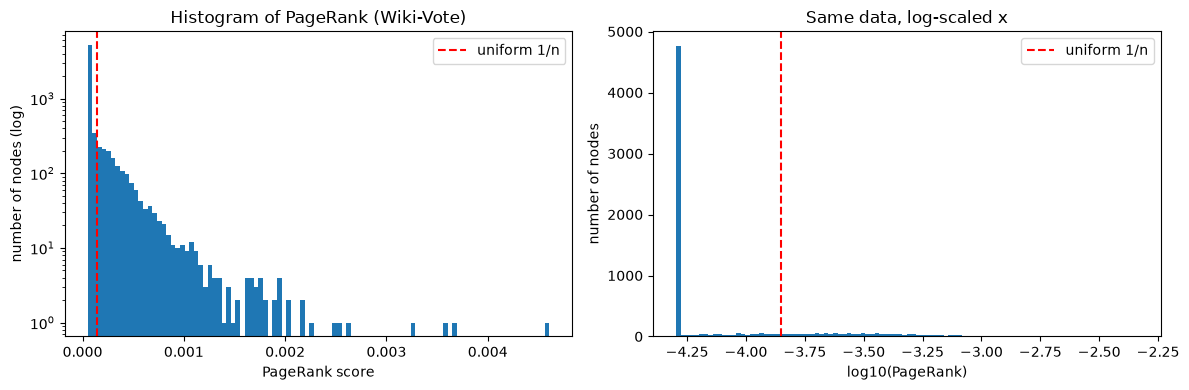

min = 5.05e-05, median = 5.05e-05, mean = 1.41e-04, max = 4.61e-03
max / median = 91x
nodes below the uniform value 1/n: 77.6%
nodes sitting at the minimum score (no in-links): 66.5%
share of total PageRank held by top 1% of nodes: 12.0%


In [12]:
fig, axes = plot.subplots(1, 2, figsize=(12, 4))
axes[0].hist(r_wiki, bins=100)
axes[0].set_yscale("log")
axes[0].axvline(1 / n_w, color="red", ls="--", label="uniform 1/n")
axes[0].set_xlabel("PageRank score"); axes[0].set_ylabel("number of nodes (log)")
axes[0].set_title("Histogram of PageRank (Wiki-Vote)"); axes[0].legend()

axes[1].hist(np.log10(r_wiki), bins=100)
axes[1].axvline(np.log10(1 / n_w), color="red", ls="--", label="uniform 1/n")
axes[1].set_xlabel("log10(PageRank)"); axes[1].set_ylabel("number of nodes")
axes[1].set_title("Same data, log-scaled x"); axes[1].legend()
plot.tight_layout(); plot.show()

s = np.sort(r_wiki)[::-1]
print(f"min = {s[-1]:.2e}, median = {np.median(s):.2e}, mean = {s.mean():.2e}, max = {s[0]:.2e}")
print(f"max / median = {s[0] / np.median(s):.0f}x")
print(f"nodes below the uniform value 1/n: {np.mean(r_wiki < 1/n_w):.1%}")
print(f"nodes sitting at the minimum score (no in-links): {np.mean(np.isclose(r_wiki, s[-1])):.1%}")
print(f"share of total PageRank held by top 1% of nodes: {s[:n_w // 100].sum():.1%}")

**Answers.**
- **Yes, the distribution is highly skewed (heavy right tail).** The maximum is ~91× the median and the top 1% of nodes hold ~12% of the total PageRank, while the log-scaled histogram shows a long tail towards high scores.
- **Yes, most nodes have a very small score.** 77.6% of all nodes are below the uniform value 1/n, and 66.5% sit exactly at the minimum score (1−d)/n + (dangling share) ≈ 5.05e-5: these users never received a vote (in-degree 0), so the only way to reach them is by teleportation. This produces the large spike at the left of the histogram.

### 6.2 Compare damping factors

Run PageRank with different damping factors and compare:
- `d = 0.70`, `0.85`, `0.95`

Tasks:
1. Compute rank vectors for each `d`
2. Compare the **top-10 overlap** between settings
3. Compute L1 distances between the resulting rank vectors

Answer briefly:
- Which nodes are stable across damping factors?
- Does higher `d` concentrate more probability on a smaller set of nodes?


In [13]:
ds = [0.70, 0.85, 0.95]
ranks = {d: PageRank_Sparse(W, d=d) for d in ds}
tops = {d: set(wiki_nodes[np.argsort(-ranks[d])[:10]]) for d in ds}

print("Top-10 per damping factor:")
for d in ds:
    print(f"  d={d:.2f}:", [int(x) for x in wiki_nodes[np.argsort(-ranks[d])[:10]]])

print("\nTop-10 overlap / L1 distance:")
for a, b in [(0.70, 0.85), (0.85, 0.95), (0.70, 0.95)]:
    print(f"  d={a:.2f} vs d={b:.2f}: overlap {len(tops[a] & tops[b])}/10, "
          f"L1 = {np.abs(ranks[a] - ranks[b]).sum():.4f}")

stable = set.intersection(*tops.values())
print("\nIn the top-10 for all three d:", sorted(int(x) for x in stable))

print("\nConcentration:")
for d in ds:
    s = np.sort(ranks[d])[::-1]
    print(f"  d={d:.2f}: top-10 mass = {s[:10].sum():.4f}, top-1% mass = {s[:n_w // 100].sum():.4f}, "
          f"max = {s[0]:.5f}, min = {s[-1]:.2e}")

Top-10 per damping factor:
  d=0.70: [4037, 15, 2625, 6634, 2470, 2237, 2398, 1186, 4191, 5254]
  d=0.85: [4037, 15, 6634, 2625, 2398, 2470, 2237, 4191, 7553, 5254]
  d=0.95: [4037, 6634, 15, 2625, 2398, 2237, 4191, 2470, 7553, 5254]

Top-10 overlap / L1 distance:
  d=0.70 vs d=0.85: overlap 9/10, L1 = 0.1516
  d=0.85 vs d=0.95: overlap 10/10, L1 = 0.1016
  d=0.70 vs d=0.95: overlap 9/10, L1 = 0.2527

In the top-10 for all three d: [15, 2237, 2398, 2470, 2625, 4037, 4191, 5254, 6634]

Concentration:
  d=0.70: top-10 mass = 0.0258, top-1% mass = 0.1030, max = 0.00427, min = 6.49e-05
  d=0.85: top-10 mass = 0.0294, top-1% mass = 0.1197, max = 0.00461, min = 5.05e-05
  d=0.95: top-10 mass = 0.0317, top-1% mass = 0.1312, max = 0.00473, min = 4.12e-05


**Answers.**
- **Stable nodes:** 9 of the 10 top nodes are identical for all three damping factors — 4037, 15, 6634, 2625, 2398, 2470, 2237, 4191, 5254 — and 4037 is #1 in every setting. Only the 10th place changes (1186 for d = 0.70, 7553 for d = 0.85/0.95), and the order inside the top-10 shifts slightly (e.g. 6634 climbs from 4th to 2nd as d grows). The ranking of the most important users is therefore robust to the choice of d.
- **Concentration:** Yes. With larger d the walker teleports less and follows the vote structure more, so mass flows towards the well-endorsed nodes: the top-10 mass rises 0.0258 → 0.0294 → 0.0317, the top-1% mass rises 10.3% → 12.0% → 13.1%, and the minimum score (nodes reached only by teleport) falls 6.5e-5 → 5.1e-5 → 4.1e-5. The L1 distances (0.15, 0.10, 0.25) show the whole vector changes noticeably even though the top of the ranking hardly does. For d → 0 the vector would approach the uniform distribution.

### 6.3 Relationship with out-degree

Compute correlation between PageRank and out-degree.

Questions:
- Are high PageRank nodes necessarily high out-degree nodes?
- What do you observe in the scatter plot?


Pearson  corr(PageRank, out-degree) = 0.254


Spearman corr(PageRank, out-degree) = -0.000
Pearson  corr(PageRank, in-degree)  = 0.922   (for comparison)
Spearman corr(PageRank, in-degree)  = 0.995

Top-10 PageRank nodes have out-degrees [241, 62, 50, 33, 20, 15, 3, 0, 0, 0]
(median out-degree of all nodes: 2, 99th percentile: 202)
nodes with out-degree 0 (never voted): 14.1%


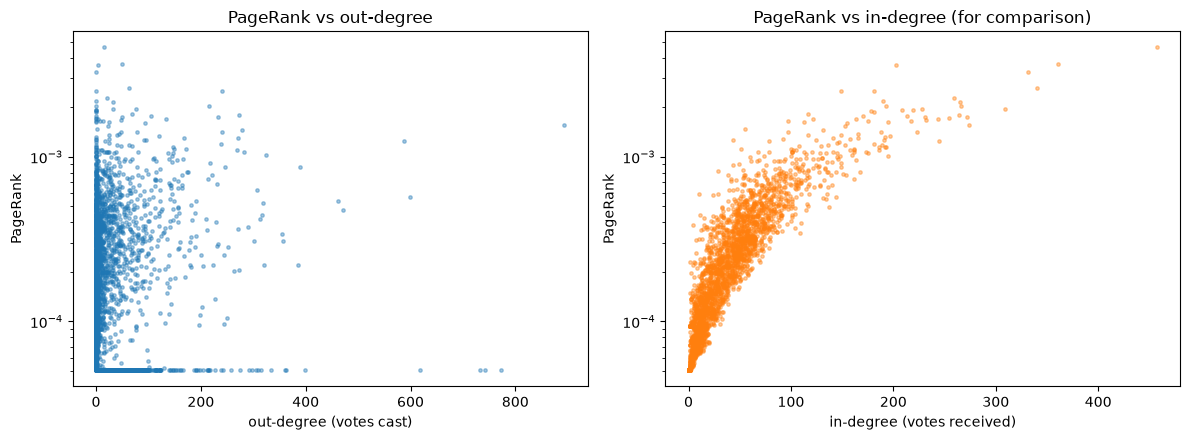

In [14]:
out_deg = np.array([W.out_degree(v) for v in wiki_nodes])
in_deg = np.array([W.in_degree(v) for v in wiki_nodes])

print(f"Pearson  corr(PageRank, out-degree) = {np.corrcoef(r_wiki, out_deg)[0, 1]:.3f}")
print(f"Spearman corr(PageRank, out-degree) = {pd.Series(r_wiki).corr(pd.Series(out_deg), method='spearman'):.3f}")
print(f"Pearson  corr(PageRank, in-degree)  = {np.corrcoef(r_wiki, in_deg)[0, 1]:.3f}   (for comparison)")
print(f"Spearman corr(PageRank, in-degree)  = {pd.Series(r_wiki).corr(pd.Series(in_deg), method='spearman'):.3f}")
print(f"\nTop-10 PageRank nodes have out-degrees {sorted(top10['out_degree (votes cast)'], reverse=True)}")
print(f"(median out-degree of all nodes: {np.median(out_deg):.0f}, 99th percentile: {np.percentile(out_deg, 99):.0f})")
print(f"nodes with out-degree 0 (never voted): {np.mean(out_deg == 0):.1%}")

fig, axes = plot.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(out_deg, r_wiki, s=6, alpha=0.4)
axes[0].set_xlabel("out-degree (votes cast)"); axes[0].set_ylabel("PageRank"); axes[0].set_yscale("log")
axes[0].set_title("PageRank vs out-degree")
axes[1].scatter(in_deg, r_wiki, s=6, alpha=0.4, color="tab:orange")
axes[1].set_xlabel("in-degree (votes received)"); axes[1].set_ylabel("PageRank"); axes[1].set_yscale("log")
axes[1].set_title("PageRank vs in-degree (for comparison)")
plot.tight_layout(); plot.show()

**Answers.**
- **No, high PageRank nodes are not necessarily high out-degree nodes.** The correlation with out-degree is weak (Pearson ≈ 0.25, Spearman ≈ 0.00). Among the top-10, three nodes (2625, 2470, 7553) have out-degree **0** — they never voted at all — and others cast only 3 or 15 votes; only 2237 (241 votes cast) is a very active voter. This is expected: PageRank flows *along* edges, so a node's score comes from its **in**-links (votes received). Casting votes only gives one's own rank away. For comparison, the correlation with in-degree is very high (Pearson ≈ 0.92, Spearman ≈ 0.995).
- **Scatter plot:** The out-degree plot is a wide, unstructured cloud: at any out-degree, PageRank spans more than an order of magnitude, there is a horizontal band of nodes at the minimum score across all out-degrees (users who vote but receive no votes), and several of the highest scores sit at out-degree 0. The in-degree plot, in contrast, shows a tight, almost monotone increasing curve, with the remaining spread caused by *who* the votes come from (inherited influence).